Malick Sonko Random Forest Model

Current directory: /Users/malick/Documents/GitHubRepositories/Chemical-Carcinogenicity-Prediction/notebooks
Found training folder at: ../data/training
--- Model Performance ---
Accuracy:  0.8411
Precision: 0.8798
Recall:    0.7347
ROC-AUC:   0.9374


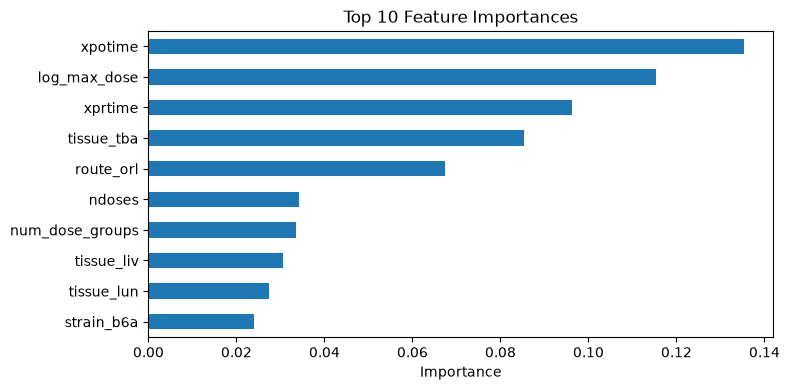

In [1]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

import os
from pathlib import Path

# Print where Jupyter is currently running
print("Current directory:", os.getcwd())

# Search parent and child folders for X_train.csv
for root in [Path('.'), Path('..'), Path('../..')]:
    matches = list(root.rglob('X_train.csv'))
    if matches:
        data_dir = matches[0].parent
        print("Found training folder at:", data_dir)
        break

# Load the team's pre-split data
X_train = pd.read_csv('../data/training/X_train.csv')
X_test = pd.read_csv('../data/training/X_test.csv')
y_train = pd.read_csv('../data/training/y_train.csv').values.ravel()
y_test = pd.read_csv('../data/training/y_test.csv').values.ravel()

# Fit Random Forest
model = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Evaluate performance
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print("--- Model Performance ---")
print(f"Accuracy:  {accuracy_score(y_test, preds):.4f}")
print(f"Precision: {precision_score(y_test, preds):.4f}")
print(f"Recall:    {recall_score(y_test, preds):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, probs):.4f}")

# Plot feature importances
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
importances.head(10).plot(kind='barh', title='Top 10 Feature Importances')
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.tight_layout()
plt.show()